# 1. Среда и воспроизводимость

Я настроил ноутбук для Google Colab с GPU T4. Фиксирую `seed = 42` для Python, NumPy, PyTorch и CUDA, чтобы повторять разбиение и проверку модели в одной и той же среде. Сохранённые выводы я получил при проверке на CPU с резервным набором ISIC 2016.

In [1]:
!pip install -q albumentations imagehash datasets huggingface_hub opencv-python-headless

import os
import random
from hashlib import sha256
from http.client import HTTPException
from io import BytesIO
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen
from zipfile import BadZipFile, ZipFile
import json
import re

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import albumentations as A
import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, get_worker_info
from tqdm.auto import tqdm

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
cv2.setNumThreads(1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_name = torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU"
print(f"Использую устройство {device} ({device_name}), seed = {seed}.")

Использую устройство cpu (CPU), seed = 42.


# 2. Загрузка дерматоскопических снимков и масок

Я беру обучающие данные ISIC 2018 Task 1. Если основной источник недоступен, загружаю обучающие данные ISIC 2016 Task 1 из официального архива. Оба источника открываются без токенов. Я сопоставляю файлы по идентификатору ISIC, сохраняю JPEG в `data/images` и PNG с пикселями 0 и 1 в `data/masks`. Для основного набора я учитываю около 22 ГБ свободного места под ZIP и распакованные пары.

Я использую [официальные архивы ISIC](https://challenge.isic-archive.com/data/). Данные ISIC 2018 доступны по CC BY-NC, данные ISIC 2016 — по CC0. В ISIC 2018 входят [HAM10000](https://doi.org/10.1038/sdata.2018.161) группы ViDIR Венского медицинского университета и снимки MSK, описанные в [статье о ISIC 2017](https://arxiv.org/abs/1710.05006) и [статье о ISIC 2018](https://arxiv.org/abs/1902.03368).

Загрузил 900 пар из ISIC 2016 Task 1.


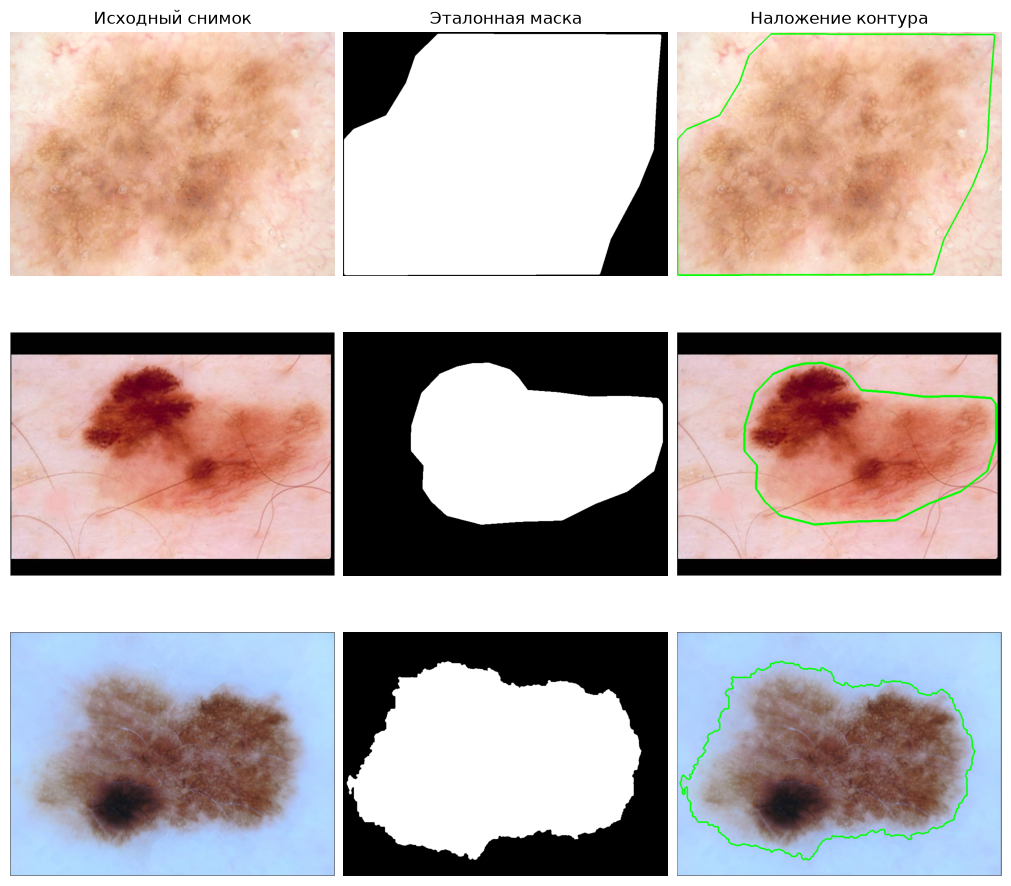

In [2]:
archive_base = "https://isic-archive.s3.amazonaws.com/challenges"
data_sources = (
    (
        "ISIC 2018 Task 1",
        2594,
        f"{archive_base}/2018/ISIC2018_Task1-2_Training_Input.zip",
        f"{archive_base}/2018/ISIC2018_Task1_Training_GroundTruth.zip",
    ),
    (
        "ISIC 2016 Task 1",
        900,
        f"{archive_base}/2016/ISBI2016_ISIC_Part1_Training_Data.zip",
        f"{archive_base}/2016/ISBI2016_ISIC_Part1_Training_GroundTruth.zip",
    ),
)


def download_archive(url, archive_dir):
    destination = archive_dir / url.rsplit("/", 1)[-1]
    if destination.is_file():
        try:
            with ZipFile(destination):
                return destination
        except BadZipFile:
            destination.unlink()

    partial = destination.with_suffix(".zip.part")
    try:
        with urlopen(url, timeout=45) as response, partial.open("wb") as output:
            total = response.headers.get("Content-Length")
            with tqdm(
                total=int(total) if total else None,
                desc=f"Скачиваю {destination.name}",
                unit="Б",
                unit_scale=True,
                leave=False,
            ) as progress:
                while chunk := response.read(1024 * 1024):
                    output.write(chunk)
                    progress.update(len(chunk))
        with ZipFile(partial):
            pass
        partial.replace(destination)
    finally:
        partial.unlink(missing_ok=True)
    return destination


def index_archive(archive, filename_pattern):
    members = {}
    for member in archive.infolist():
        match = re.fullmatch(filename_pattern, Path(member.filename).name, re.IGNORECASE)
        if member.is_dir() or not match:
            continue
        image_id = match.group(1).upper()
        if image_id in members:
            raise ValueError(f"Нашёл повторяющийся идентификатор {image_id} внутри архива.")
        members[image_id] = member
    return members


def prepare_pairs(root, source):
    source_name, expected_count, image_url, mask_url = source
    archive_dir = root / ".archives"
    archive_dir.mkdir(exist_ok=True)
    mask_archive = download_archive(mask_url, archive_dir)
    image_archive = download_archive(image_url, archive_dir)

    with (
        ZipFile(image_archive) as images,
        ZipFile(mask_archive) as masks,
        TemporaryDirectory(dir=root) as staging_dir,
    ):
        image_members = index_archive(images, r"(ISIC_\d+)\.jpe?g")
        mask_members = index_archive(masks, r"(ISIC_\d+)(?:_segmentation)?\.png")
        if len(image_members) != expected_count or image_members.keys() != mask_members.keys():
            raise ValueError(
                f"Ожидал {expected_count} совпадающих пар, получил "
                f"{len(image_members)} снимков и {len(mask_members)} масок."
            )

        image_ids = sorted(image_members)
        staging = Path(staging_dir)
        for image_id in tqdm(image_ids, desc="Сохраняю пары", leave=False):
            jpeg_bytes = images.read(image_members[image_id])
            with (
                Image.open(BytesIO(jpeg_bytes)) as image,
                Image.open(BytesIO(masks.read(mask_members[image_id]))) as mask,
            ):
                if image.size != mask.size:
                    raise ValueError(f"Размеры снимка и маски {image_id} различаются.")
                image_path = staging / f"{image_id}.jpg"
                if image.mode == "RGB":
                    image_path.write_bytes(jpeg_bytes)
                else:
                    image.convert("RGB").save(image_path, quality=95)
                binary_mask = (np.asarray(mask.convert("L")) > 0).astype(np.uint8)
                Image.fromarray(binary_mask).save(staging / f"{image_id}.png")

        for image_id in image_ids:
            (staging / f"{image_id}.jpg").replace(root / "images" / f"{image_id}.jpg")
            (staging / f"{image_id}.png").replace(root / "masks" / f"{image_id}.png")
        manifest = staging / "dataset.json"
        manifest.write_text(
            json.dumps({"source": source_name, "image_ids": image_ids}), encoding="utf-8"
        )
        manifest.replace(root / "dataset.json")

    return image_ids


def load_skin_lesions(data_dir="data"):
    root = Path(data_dir)
    for directory in (root / "images", root / "masks"):
        directory.mkdir(parents=True, exist_ok=True)

    def pair_paths(image_ids):
        return [
            (root / "images" / f"{image_id}.jpg", root / "masks" / f"{image_id}.png")
            for image_id in image_ids
        ]

    manifest_path = root / "dataset.json"
    expected_counts = {name: count for name, count, *_ in data_sources}
    if manifest_path.is_file():
        try:
            manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
            source_name, image_ids = manifest["source"], manifest["image_ids"]
            pairs = pair_paths(image_ids)
            if len(pairs) == expected_counts.get(source_name) and all(
                image.is_file() and mask.is_file() for image, mask in pairs
            ):
                return source_name, pairs
        except (OSError, KeyError, TypeError, ValueError):
            print("Не смог прочитать список сохранённых пар. Подготавливаю данные заново.")

    errors = []
    for source in data_sources:
        source_name = source[0]
        try:
            return source_name, pair_paths(prepare_pairs(root, source))
        except (OSError, HTTPException, ValueError, BadZipFile) as error:
            errors.append(f"{source_name} — {error}")
            print(f"Не смог подготовить {source_name}. {error}")

    raise RuntimeError("Не смог загрузить ни один набор. " + " | ".join(errors))


dataset_name, pairs = load_skin_lesions()
print(f"Загрузил {len(pairs):,} пар из {dataset_name}.".replace(",", " "))

figure, axes = plt.subplots(3, 3, figsize=(10, 9), layout="constrained")
examples = random.Random(seed).sample(pairs, k=3)
for row, (image_path, mask_path) in enumerate(examples):
    with Image.open(image_path) as image_file, Image.open(mask_path) as mask_file:
        image = np.array(image_file.convert("RGB"))
        mask = np.array(mask_file, dtype=np.uint8)

    contours, _ = cv2.findContours(mask, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    overlay = image.copy()
    cv2.drawContours(overlay, contours, -1, (0, 255, 0), max(2, round(min(mask.shape) / 200)))
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].imshow(overlay)
    for axis in axes[row]:
        axis.axis("off")

for axis, title in zip(axes[0], ("Исходный снимок", "Эталонная маска", "Наложение контура")):
    axis.set_title(title)
plt.show()

# 3. Дисбаланс пикселей, дубликаты и разбиение

Я измеряю долю очага на исходных масках, до ресайза и аугментаций. Сначала нахожу точные копии по SHA-256 декодированных RGB-пикселей. Затем объединяю оставшиеся снимки в группы по pHash с расстоянием Хэмминга до 4 включительно. Если два снимка связаны через третий, я оставляю один снимок на всю группу. После очистки делю пары на train, val и test в пропорции 80/10/10. Проверка по pHash снижает риск утечки похожих кадров; принадлежность снимков одному пациенту я здесь не проверяю.

In [3]:
def find_unique_indices(pairs, max_distance=4):
    unique_pixels = set()
    candidates = []
    hashes = []
    for index, (image_path, _) in enumerate(tqdm(pairs, desc="Считаю pHash", leave=False)):
        with Image.open(image_path) as photo:
            rgb = photo.convert("RGB")
            pixel_key = (rgb.size, sha256(rgb.tobytes()).digest())
            perceptual_hash = int(str(imagehash.phash(rgb)), 16)
        if pixel_key in unique_pixels:
            continue
        unique_pixels.add(pixel_key)
        candidates.append(index)
        hashes.append(perceptual_hash)

    parents = list(range(len(candidates)))

    def find_root(index):
        while parents[index] != index:
            parents[index] = parents[parents[index]]
            index = parents[index]
        return index

    for right, right_hash in enumerate(hashes):
        for left in range(right):
            if (hashes[left] ^ right_hash).bit_count() <= max_distance:
                first, second = sorted((find_root(left), find_root(right)))
                parents[second] = first

    keep = [original for index, original in enumerate(candidates) if index == find_root(index)]
    return keep, len(pairs) - len(candidates), len(candidates) - len(keep)


lesion_fractions = []
for _, mask_path in pairs:
    with Image.open(mask_path) as mask:
        lesion_fractions.append(np.asarray(mask).mean())
lesion_fractions = np.asarray(lesion_fractions)

print(
    f"Измерил долю очага по снимкам. Средняя — {lesion_fractions.mean():.2%}, "
    f"медианная — {np.median(lesion_fractions):.2%}, "
    f"минимальная — {lesion_fractions.min():.2%}, максимальная — {lesion_fractions.max():.2%}."
)
print(f"Средняя доля фона — {1 - lesion_fractions.mean():.2%}.")

keep_indices, exact_duplicates, near_duplicates = find_unique_indices(pairs)
clean_pairs = [pairs[index] for index in keep_indices]
print(
    f"Удалил {exact_duplicates + near_duplicates} повторов. "
    f"Точных — {exact_duplicates}, близких по pHash — {near_duplicates}. "
    f"Оставил {len(clean_pairs)} пар."
)

order = np.random.default_rng(seed).permutation(len(clean_pairs))
holdout_size = round(0.10 * len(order))
val_end = 2 * holdout_size
test_pairs = [clean_pairs[index] for index in order[:holdout_size]]
val_pairs = [clean_pairs[index] for index in order[holdout_size:val_end]]
train_pairs = [clean_pairs[index] for index in order[val_end:]]

for name, split in (("train", train_pairs), ("val", val_pairs), ("test", test_pairs)):
    print(f"{name} — {len(split)} пар ({len(split) / len(clean_pairs):.1%}).")

Измерил долю очага по снимкам. Средняя — 27.09%, медианная — 21.35%, минимальная — 1.16%, максимальная — 99.54%.
Средняя доля фона — 72.91%.


Удалил 9 повторов. Точных — 1, близких по pHash — 8. Оставил 891 пар.
train — 713 пар (80.0%).
val — 89 пар (10.0%).
test — 89 пар (10.0%).


# 4. Dataset, ресайз и аугментации

Я привожу снимки и маски к 256 × 256. Для масок при ресайзе и геометрических преобразованиях использую ближайшего соседа, чтобы сохранить метки 0 и 1. Сдвигаю, отражаю и поворачиваю только обучающие пары. Я нормализую RGB по ImageNet во всех выборках, а яркость и контраст меняю только у обучающих снимков.

In [4]:
image_size = 256
batch_size = 16
num_workers = 2
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)

train_transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.ShiftScaleRotate(
            p=0.5,
            interpolation=cv2.INTER_LINEAR,
            mask_interpolation=cv2.INTER_NEAREST,
            border_mode=cv2.BORDER_CONSTANT,
        ),
        A.RandomBrightnessContrast(p=0.3),
        A.Normalize(mean=imagenet_mean, std=imagenet_std),
    ],
    seed=seed,
)
eval_transform = A.Compose([A.Normalize(mean=imagenet_mean, std=imagenet_std)])


class SkinLesionDataset(torch.utils.data.Dataset):
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        with Image.open(image_path) as image_file, Image.open(mask_path) as mask_file:
            image = np.array(image_file.convert("RGB"))
            mask = np.array(mask_file, dtype=np.uint8)

        size = (image_size, image_size)
        image = cv2.resize(image, size, interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, size, interpolation=cv2.INTER_NEAREST)
        augmented = self.transform(image=image, mask=mask)
        image_tensor = torch.from_numpy(augmented["image"]).permute(2, 0, 1).contiguous()
        mask_tensor = torch.from_numpy(augmented["mask"]).unsqueeze(0).float()
        return image_tensor, mask_tensor


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)
    cv2.setNumThreads(1)
    get_worker_info().dataset.transform.set_random_seed(worker_seed)


train_dataset = SkinLesionDataset(train_pairs, train_transform)
val_dataset = SkinLesionDataset(val_pairs, eval_transform)
test_dataset = SkinLesionDataset(test_pairs, eval_transform)

loader_settings = dict(
    batch_size=batch_size,
    num_workers=num_workers,
    pin_memory=True,
    worker_init_fn=seed_worker,
)
train_generator = torch.Generator().manual_seed(seed)
train_loader = DataLoader(
    train_dataset, shuffle=True, generator=train_generator, **loader_settings
)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_settings)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_settings)

sample_images, sample_masks = next(iter(train_loader))
train_generator.manual_seed(seed)
assert sample_images.shape == (batch_size, 3, image_size, image_size)
assert sample_masks.shape == (batch_size, 1, image_size, image_size)
assert torch.all((sample_masks == 0) | (sample_masks == 1))
print(f"Проверил батч. Снимки {tuple(sample_images.shape)}, маски {tuple(sample_masks.shape)}.")

Проверил батч. Снимки (16, 3, 256, 256), маски (16, 1, 256, 256).


# 5. U-Net и комбинированный лосс

Я собрал четыре уровня энкодера с шагами 32 → 64 → 128 → 256 каналов и блок на 512 каналов между энкодером и декодером. На каждом шаге декодера удваиваю разрешение и конкатенирую результат с признаками энкодера. Свёртка 1 × 1 выдаёт один логит на пиксель.

$$
\mathcal{L} = 1 - \text{Dice} + \lambda \mathcal{L}_{\text{focal}}
$$

Я считаю Dice по вероятностям отдельно для каждого снимка, затем усредняю. Focal считаю по логитам через `binary_cross_entropy_with_logits` с весом `alpha = 0.25` для очага, `1 - alpha` для фона и `gamma = 2.0`. Беру `lambda_focal = 1.0` и `smooth = 1e-6`. На CUDA я включаю AMP для прямого прохода модели и считаю лосс в FP32. На CPU проверяю тот же батч частями, чтобы ограничить расход памяти.

Я использую модель для выделения области интереса для специалиста. Маска сама по себе не является диагнозом.

In [5]:
def double_conv(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        channels = (32, 64, 128, 256)
        self.encoder = nn.ModuleList(
            double_conv(in_channels, out_channels)
            for in_channels, out_channels in zip((3, *channels), channels)
        )
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.bottleneck = double_conv(256, 512)
        self.upsample = nn.ModuleList(
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
            for in_channels, out_channels in zip((512, 256, 128, 64), reversed(channels))
        )
        self.decoder = nn.ModuleList(
            double_conv(2 * channel, channel) for channel in reversed(channels)
        )
        self.head = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, images):
        features = images
        skips = []
        for down in self.encoder:
            features = down(features)
            skips.append(features)
            features = self.pool(features)
        features = self.bottleneck(features)
        for up, decode, skip in zip(self.upsample, self.decoder, reversed(skips)):
            features = decode(torch.cat((up(features), skip), dim=1))
        return self.head(features)


class DiceFocalLoss(nn.Module):
    def __init__(self, lambda_focal=1.0, alpha=0.25, gamma=2.0, smooth=1e-6):
        super().__init__()
        self.lambda_focal = lambda_focal
        self.alpha = alpha
        self.gamma = gamma
        self.smooth = smooth

    def forward(self, logits, targets):
        logits, targets = logits.float(), targets.float()
        probabilities = logits.sigmoid().flatten(1)
        flat_targets = targets.flatten(1)
        intersection = (probabilities * flat_targets).sum(dim=1)
        dice = (2 * intersection + self.smooth) / (
            probabilities.sum(dim=1) + flat_targets.sum(dim=1) + self.smooth
        )

        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        p_t = (-bce).exp()
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        focal = (alpha_t * (1 - p_t).pow(self.gamma) * bce).mean()
        return 1 - dice.mean() + self.lambda_focal * focal


model = UNet().to(device)
criterion = DiceFocalLoss()
use_amp = device.type == "cuda"
micro_batch_size = batch_size if use_amp else 2
check_loss = torch.zeros((), device=device)

# Замораживаю статистики BatchNorm, чтобы проверочный проход не менял состояние модели.
model.eval()
try:
    for images, masks in zip(sample_images.split(micro_batch_size), sample_masks.split(micro_batch_size)):
        images = images.to(device, non_blocking=use_amp)
        masks = masks.to(device, non_blocking=use_amp)
        with torch.amp.autocast(device_type=device.type, enabled=use_amp):
            logits = model(images)
        assert logits.shape == masks.shape, (logits.shape, masks.shape)
        loss = criterion(logits, masks) * (len(images) / len(sample_images))
        loss.backward()
        check_loss += loss.detach()

    gradients = [parameter.grad for parameter in model.parameters() if parameter.requires_grad]
    assert torch.isfinite(check_loss), "Проверочный лосс вышел за пределы конечных чисел."
    assert all(gradient is not None for gradient in gradients), "У части параметров нет градиентов."
    gradient_norms = torch.stack([gradient.norm() for gradient in gradients])
    assert torch.isfinite(gradient_norms).all(), "Нашёл NaN или Inf в градиентах."
    assert gradient_norms.max() > 0, "Все градиенты нулевые."
    print(f"Проверил логиты {tuple(sample_masks.shape)}. Dice + Focal Loss = {check_loss.item():.6f}.")
    print("Проверил backward. У всех обучаемых параметров есть конечные градиенты.")
finally:
    model.zero_grad(set_to_none=True)
    model.train()

Проверил логиты (16, 1, 256, 256). Dice + Focal Loss = 0.760277.
Проверил backward. У всех обучаемых параметров есть конечные градиенты.
